# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

A Kampala matatu association wants to compare demand and gross fare revenue on three routes, evaluate the given Ntinda supply–demand model, forecast day-11 demand, and estimate fleet deployment.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'src').exists() and (PROJECT_ROOT.parent/'src').exists():
    PROJECT_ROOT=PROJECT_ROOT.parent
sys.path.insert(0,str(PROJECT_ROOT)) if str(PROJECT_ROOT) not in sys.path else None
from src.taxi_model import Route, Forecaster, MovingAverageForecaster, ExponentialSmoothingForecaster, LinearTrendForecaster, solve_ntinda_equilibrium, forecast_factory
SEED=2026
rng=np.random.default_rng(SEED)
plt.rcParams['figure.figsize']=(10,5)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-4fd4_y2b because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1. Route objects, descriptive statistics, and gross revenue

In [2]:
routes={
 "Kampala–Ntinda":Route("Kampala–Ntinda",np.array([35,40,42,50,55,60,48,52,47,45]),2000),
 "Kampala–Entebbe":Route("Kampala–Entebbe",np.array([60,58,65,70,72,80,75,68,66,64]),5000),
 "Kampala–Mukono":Route("Kampala–Mukono",np.array([45,47,50,49,55,62,58,53,51,50]),3000),
}
days=np.arange(1,11)
rows=[]
for r in routes.values():
    s=r.descriptive_statistics()
    rows.append({"Route":r.name,"Fare (UGX)":r.fare_ugx,"Mean passengers/day":s["mean"],
                 "Sample variance (passengers²)":s["variance"],"Sample SD (passengers)":s["standard_deviation"],
                 "10-day gross revenue (UGX)":r.total_revenue()})
summary=pd.DataFrame(rows)
display(summary.round(2))

,Route,Fare (UGX),Mean passengers/day,Sample variance (passengers²),Sample SD (passengers),10-day gross revenue (UGX)
0,Kampala–Ntinda,2000,47.4,54.27,7.37,948000.0
1,Kampala–Entebbe,5000,67.8,45.07,6.71,3390000.0
2,Kampala–Mukono,3000,52.0,26.44,5.14,1560000.0


`statistics.variance` and `statistics.stdev` calculate sample statistics. Variance is measured in passengers squared; standard deviation is in passengers. Gross revenue excludes fuel, wages, maintenance, and other costs.

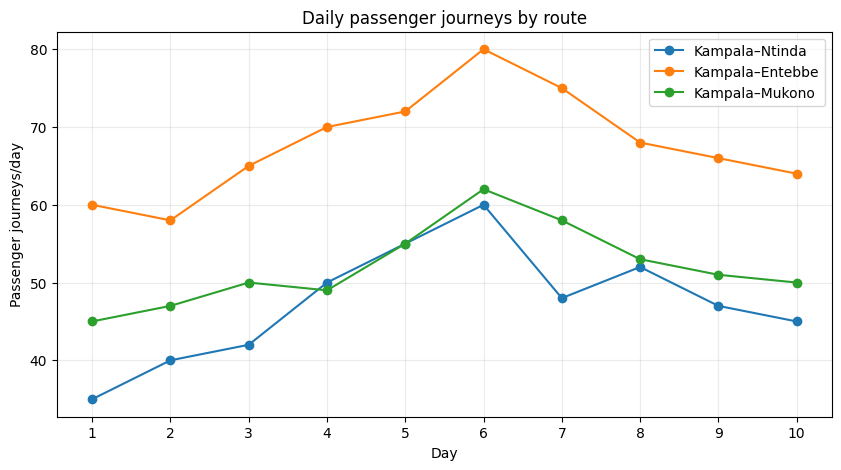

In [3]:
fig,ax=plt.subplots()
for r in routes.values(): ax.plot(days,r.passenger_counts,marker='o',label=r.name)
ax.set(title="Daily passenger journeys by route",xlabel="Day",ylabel="Passenger journeys/day")
ax.set_xticks(days); ax.grid(alpha=.25); ax.legend(); plt.show()

## 2. Solve Ntinda supply–demand equilibrium

In [4]:
eq=solve_ntinda_equilibrium()
p_star,q_star=eq["price_ugx"],eq["quantity"]
current_fare=routes["Kampala–Ntinda"].fare_ugx
print(f"Equilibrium fare = UGX {p_star:,.0f}")
print(f"Equilibrium quantity = {q_star:.1f} passengers per trip-hour")
print(f"At current fare UGX {current_fare:,.0f}: demand={120-.02*current_fare:.1f}, supply={10+.03*current_fare:.1f}")
print("Current fare is below the modelled equilibrium fare." if current_fare<p_star else "Current fare is at or above the modelled equilibrium fare.")

Equilibrium fare = UGX 2,200
Equilibrium quantity = 76.0 passengers per trip-hour
At current fare UGX 2,000: demand=80.0, supply=70.0
Current fare is below the modelled equilibrium fare.


The equilibrium condition is \(120-0.02P=10+0.03P\), giving \(P^*=2,200\) UGX and \(Q^*=76\). At UGX 2,000, the equations imply demand of 80 and supply of 70, or excess demand of 10 passengers per trip-hour. The result follows from the assignment's assumed curves and is not a real fare recommendation: empirical demand, operating costs, regulations, and vehicle capacity are not estimated here.

## 3. Forecasters and walk-forward backtesting (days 4–10)

In [5]:
MODEL_NAMES=["3-day moving average","simple exponential smoothing","linear trend"]
ALPHAS=np.round(np.arange(.1,1.01,.1),2)
def make_model(name,alpha=.3): return forecast_factory(name,alpha)
def walk_forward(values,name,alpha=.3,start_index=3):
    values=np.asarray(values,dtype=float); out=[]
    for i in range(start_index,len(values)):
        model=make_model(name,alpha).fit(values[:i])
        out.append(float(model.predict(1)[0]))
    return np.asarray(out)
def mae(actual,pred): return float(np.mean(np.abs(np.asarray(actual)-np.asarray(pred))))
backtest_rows=[]; best_alpha={}
for r in routes.values():
    y=r.passenger_counts
    scores={float(a):mae(y[3:],walk_forward(y,"simple exponential smoothing",float(a),3)) for a in ALPHAS}
    alpha=min(scores,key=scores.get); best_alpha[r.name]=alpha
    for name in MODEL_NAMES:
        a=alpha if name=="simple exponential smoothing" else .3
        pred=walk_forward(y,name,a,3)
        backtest_rows.append({"Route":r.name,"Model":name,"MAE (passengers/day)":mae(y[3:],pred),
                              "Tuned alpha":a if name=="simple exponential smoothing" else np.nan})
backtest=pd.DataFrame(backtest_rows)
display(backtest.round(3))
print("Selected alpha by route:",best_alpha)

,Route,Model,MAE (passengers/day),Tuned alpha
0,Kampala–Ntinda,3-day moving average,7.524,NaN
1,Kampala–Ntinda,simple exponential smoothing,5.857,1.0
2,Kampala–Ntinda,linear trend,7.873,NaN
3,Kampala–Entebbe,3-day moving average,7.190,NaN
4,Kampala–Entebbe,simple exponential smoothing,4.429,1.0
5,Kampala–Entebbe,linear trend,7.711,NaN
6,Kampala–Mukono,3-day moving average,5.333,NaN
7,Kampala–Mukono,simple exponential smoothing,3.714,1.0
8,Kampala–Mukono,linear trend,6.391,NaN


Selected alpha by route: {'Kampala–Ntinda': 1.0, 'Kampala–Entebbe': 1.0, 'Kampala–Mukono': 1.0}


The walk-forward test predicts day 4 using days 1–3, then expands the training history one day at a time through day 10. For simple exponential smoothing, α is selected from 0.1 to 1.0 using the days 4–10 MAE. Because this is a very small dataset and α is tuned on the same window used for comparison, the reported ranking is preliminary.

## 4. Best model and day-11 forecast

In [6]:
best_models={}; forecast_rows=[]
for r in routes.values():
    scores=backtest[backtest.Route==r.name].set_index("Model")["MAE (passengers/day)"]
    name=scores.idxmin()
    alpha=best_alpha[r.name] if name=="simple exponential smoothing" else .3
    model=make_model(name,alpha).fit(r.passenger_counts)
    demand=max(0.,float(model.predict(1)[0]))
    best_models[r.name]=(name,alpha,demand)
    forecast_rows.append({"Route":r.name,"Selected model":name,"Alpha":alpha if name=="simple exponential smoothing" else np.nan,
                          "Forecast passengers day 11":demand,"Fare (UGX)":r.fare_ugx,
                          "Forecast gross revenue day 11 (UGX)":demand*r.fare_ugx})
day11=pd.DataFrame(forecast_rows)
display(day11.round(2))

,Route,Selected model,Alpha,Forecast passengers day 11,Fare (UGX),Forecast gross revenue day 11 (UGX)
0,Kampala–Ntinda,simple exponential smoothing,1.0,45.0,2000,90000.0
1,Kampala–Entebbe,simple exponential smoothing,1.0,64.0,5000,320000.0
2,Kampala–Mukono,simple exponential smoothing,1.0,50.0,3000,150000.0


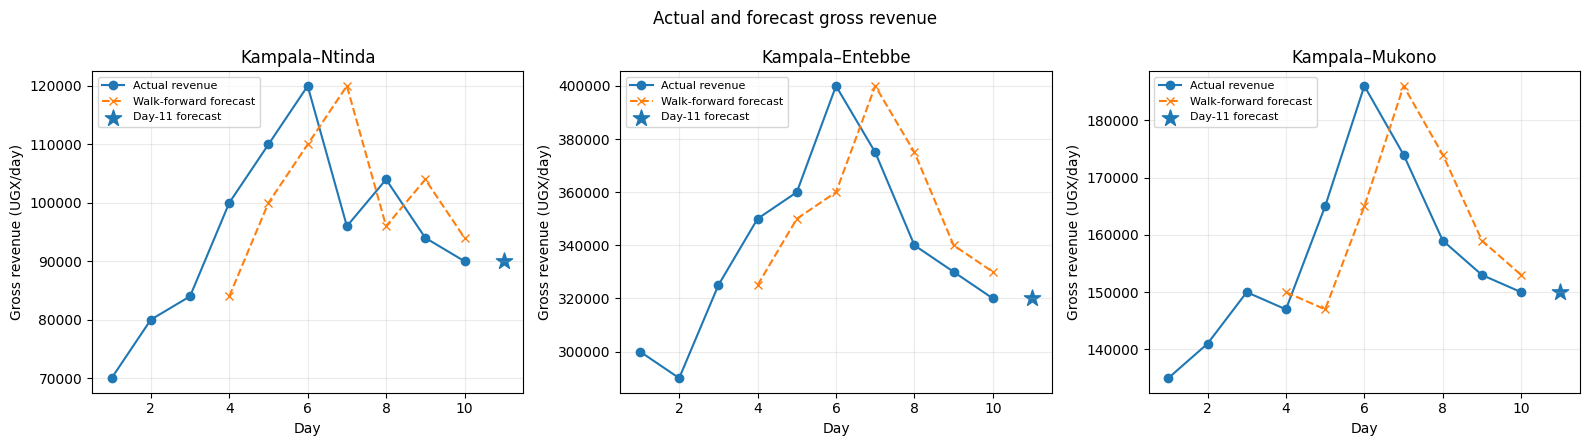

In [7]:
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for ax,r in zip(axes,routes.values()):
    name,alpha,demand=best_models[r.name]
    rolling=walk_forward(r.passenger_counts,name,alpha,3)*r.fare_ugx
    ax.plot(days,r.daily_revenue(),marker='o',label="Actual revenue")
    ax.plot(np.arange(4,11),rolling,marker='x',linestyle='--',label="Walk-forward forecast")
    ax.scatter([11],[demand*r.fare_ugx],marker='*',s=150,label="Day-11 forecast")
    ax.set(title=r.name,xlabel="Day",ylabel="Gross revenue (UGX/day)")
    ax.grid(alpha=.25); ax.legend(fontsize=8)
plt.suptitle("Actual and forecast gross revenue"); plt.tight_layout(); plt.show()

## 5. Fleet deployment with a 15% buffer

In [8]:
SEATS=14; TRIPS=8; BUFFER=.15
CAPACITY=SEATS*TRIPS
fleet=[]
for row in forecast_rows:
    demand=row["Forecast passengers day 11"]
    buffered=demand*(1+BUFFER)
    n=int(np.ceil(buffered/CAPACITY))
    fleet.append({"Route":row["Route"],"Forecast journeys/day":demand,"With 15% buffer":buffered,
                  "Vehicle capacity/day":CAPACITY,"Vehicles to deploy":n,"Nominal capacity":n*CAPACITY})
fleet_plan=pd.DataFrame(fleet)
display(fleet_plan.round(2))
print(f"Nominal vehicle capacity = {SEATS} seats × {TRIPS} one-way trips = {CAPACITY} passenger journeys/day.")

,Route,Forecast journeys/day,With 15% buffer,Vehicle capacity/day,Vehicles to deploy,Nominal capacity
0,Kampala–Ntinda,45.0,51.75,112,1,112
1,Kampala–Entebbe,64.0,73.60,112,1,112
2,Kampala–Mukono,50.0,57.50,112,1,112


Nominal vehicle capacity = 14 seats × 8 one-way trips = 112 passenger journeys/day.


Fleet size is `ceil(forecast × 1.15 / 112)`. This assumes all seats are usable on each of eight trips. Peak-hour bunching, empty return trips, breakdowns and maintenance can change the practical requirement.

## 6. Extension: 60-day weekly pattern; seasonal-naïve vs moving average

In [9]:
n=60
t=np.arange(n); weekday=t%7 # Monday=0, Sunday=6
weekday_effect=np.array([0,2,3,4,12,5,-12],dtype=float) # Friday busier, Sunday quieter
synthetic=np.maximum(5,55+weekday_effect[weekday]+rng.normal(0,2,n))
def seasonal_naive(values,start,period=7):
    values=np.asarray(values); return np.array([values[i-period] for i in range(start,len(values))])
def moving_average(values,start,window=3):
    values=np.asarray(values); return np.array([np.mean(values[max(0,i-window):i]) for i in range(start,len(values))])
split=35
seasonal_pred=seasonal_naive(synthetic,split,7)
ma_pred=moving_average(synthetic,split,3)
extension_scores=pd.DataFrame({"Model":["Seasonal-naïve (same weekday previous week)","3-day moving average"],
 "MAE (passengers/day)":[mae(synthetic[split:],seasonal_pred),mae(synthetic[split:],ma_pred)]})
display(extension_scores.round(3))

,Model,MAE (passengers/day)
0,Seasonal-naïve (same weekday previous week),2.473
1,3-day moving average,6.501


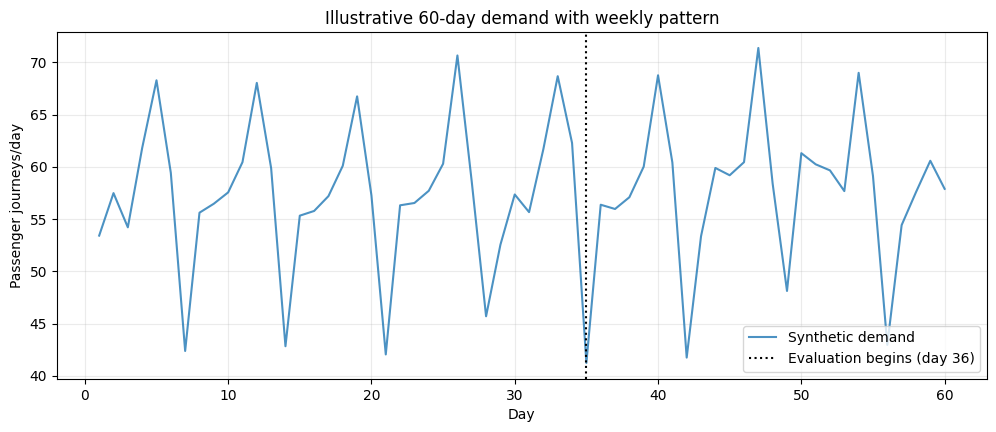

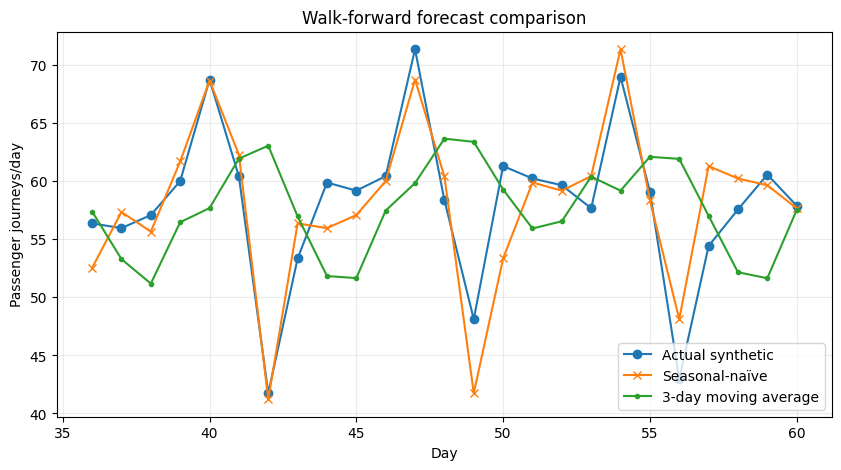

In [10]:
fig,ax=plt.subplots(figsize=(12,4.5))
ax.plot(np.arange(1,n+1),synthetic,label="Synthetic demand",alpha=.8)
ax.axvline(split,color="black",linestyle=":",label="Evaluation begins (day 36)")
ax.set(title="Illustrative 60-day demand with weekly pattern",xlabel="Day",ylabel="Passenger journeys/day")
ax.grid(alpha=.25); ax.legend(); plt.show()
fig,ax=plt.subplots()
x=np.arange(split+1,n+1)
ax.plot(x,synthetic[split:],marker='o',label="Actual synthetic")
ax.plot(x,seasonal_pred,marker='x',label="Seasonal-naïve")
ax.plot(x,ma_pred,marker='.',label="3-day moving average")
ax.set(title="Walk-forward forecast comparison",xlabel="Day",ylabel="Passenger journeys/day")
ax.grid(alpha=.25); ax.legend(); plt.show()

The seasonal-naïve method uses the same weekday seven days earlier. It is expected to capture a stable weekly pattern better than a three-day average, which smooths over weekday differences. The scores show whether it does so for this particular seeded synthetic series; they are not evidence about real Kampala traffic.

## Findings & Limitations
The route summaries combine daily passenger journeys, fare, sample variability and gross revenue. Since fares differ, the route with the most passengers need not earn the most gross revenue. Profit cannot be inferred because costs were not supplied. The Ntinda linear supply–demand equations imply an equilibrium fare of UGX 2,200 and quantity of 76 passengers per trip-hour. At UGX 2,000, the model implies demand exceeds supply, but the result depends entirely on assumed coefficients and should not be used alone to set real fares.